# BeeSkilled — Machine Learning & AI
## Week 2: Supervised Learning (Regression & Classification)
**Name:** Raman

**Focus:** Model building, training, accuracy testing

**Topics covered:** Linear Regression · Logistic Regression · Decision Tree, Random Forest · Accuracy metrics (MSE, R², Confusion Matrix)

This notebook completes:
- **Assignment 1** – Build a Linear Regression model on a housing dataset (predict price)
- **Assignment 2** – Train Logistic Regression on the Titanic dataset for survival prediction
- **Mini Project 2** – "House Price Prediction Model" on the Kaggle House Prices dataset (train Linear Regression, predict prices, evaluate R², plot predicted vs actual)
- **Practice Questions** – Classification models: Logistic Regression, confusion matrix & accuracy, Decision Tree vs KNN comparison, tuning Decision Tree `max_depth`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    confusion_matrix, classification_report,
)

plt.style.use("ggplot")
print("Libraries imported successfully")

Libraries imported successfully


---
## Datasets

- **Housing dataset (Kaggle – House Prices: Advanced Regression Techniques, train set):** 1,460 houses × 81 columns, target `SalePrice`. Loaded from the public mirror of the Kaggle train file.
- **Titanic dataset:** 891 passengers × 12 columns, target `Survived`. Same dataset as Week 1.

In [2]:
# Housing data — Kaggle House Prices train set (public mirror of the Kaggle file)
house_url = "https://raw.githubusercontent.com/xiaoxiaogao-DD/store/master/train.csv"
house = pd.read_csv(house_url)
print("House Prices shape (rows, columns):", house.shape)
assert house.shape == (1460, 81), "Unexpected House Prices shape!"
assert "SalePrice" in house.columns and house.columns[-1] == "SalePrice"
print("SalePrice column confirmed (last column). Price range: $%s - $%s"
      % (f"{house['SalePrice'].min():,}", f"{house['SalePrice'].max():,}"))
house.head()

House Prices shape (rows, columns): (1460, 81)
SalePrice column confirmed (last column). Price range: $34,900 - $755,000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# Titanic data — same source as Week 1
titanic_url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(titanic_url)
print("Titanic shape (rows, columns):", titanic.shape)
titanic.head()

Titanic shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
## Assignment 1: Linear Regression on a housing dataset (predict price)

**Idea:** house price should rise with living area, overall quality, garage size, basement area, bathrooms and how new the house is. We fit one Linear Regression on these six numeric features, split 80/20 into train/test, and judge it with MSE, RMSE and R².

In [4]:
# Assignment 1 — features and target
features_a1 = ["GrLivArea", "OverallQual", "GarageCars",
               "TotalBsmtSF", "FullBath", "YearBuilt"]
X_a1 = house[features_a1]
y_a1 = house["SalePrice"]
print("Missing values in chosen features:")
print(X_a1.isna().sum())

# Median imputation (a few GarageCars / TotalBsmtSF values are missing)
imputer_a1 = SimpleImputer(strategy="median")
X_a1 = pd.DataFrame(imputer_a1.fit_transform(X_a1), columns=features_a1)

X_train_a1, X_test_a1, y_train_a1, y_test_a1 = train_test_split(
    X_a1, y_a1, test_size=0.2, random_state=42)
print("Train:", X_train_a1.shape, "| Test:", X_test_a1.shape)

Missing values in chosen features:
GrLivArea      0
OverallQual    0
GarageCars     0
TotalBsmtSF    0
FullBath       0
YearBuilt      0
dtype: int64
Train: (1168, 6) | Test: (292, 6)


In [5]:
# Assignment 1 — train and evaluate
lr_a1 = LinearRegression()
lr_a1.fit(X_train_a1, y_train_a1)
pred_a1 = lr_a1.predict(X_test_a1)

mse_a1 = mean_squared_error(y_test_a1, pred_a1)
print("Assignment 1 — Linear Regression on housing data")
print("MSE  : $%s" % f"{mse_a1:,.0f}")
print("RMSE : $%s" % f"{np.sqrt(mse_a1):,.0f}")
print("R2   : %.4f  (about %.1f%% of price variation explained)"
      % (r2_score(y_test_a1, pred_a1), 100 * r2_score(y_test_a1, pred_a1)))

print()
print("What each feature adds to the predicted price (coefficients):")
for name, coef in zip(features_a1, lr_a1.coef_):
    print(f"  {name:12s} : ${coef:,.0f}")
print(f"  Intercept    : ${lr_a1.intercept_:,.0f}")

# Sample prediction: a 2,000 sq.ft, OverallQual 7, 2-car garage, 1,000 sq.ft basement,
# 2 full baths, built in 2005
sample_house = pd.DataFrame([[2000, 7, 2, 1000, 2, 2005]], columns=features_a1)
print()
print("Sample prediction — 2000 sq.ft, Qual 7, 2-car garage, 1000 sq.ft basement,",
      "2 baths, built 2005: $%s" % f"{lr_a1.predict(sample_house)[0]:,.0f}")

Assignment 1 — Linear Regression on housing data
MSE  : $1,576,962,755
RMSE : $39,711
R2   : 0.7944  (about 79.4% of price variation explained)

What each feature adds to the predicted price (coefficients):
  GrLivArea    : $52
  OverallQual  : $20,507
  GarageCars   : $15,329
  TotalBsmtSF  : $24
  FullBath     : $-5,421
  YearBuilt    : $351
  Intercept    : $-759,894

Sample prediction — 2000 sq.ft, Qual 7, 2-car garage, 1000 sq.ft basement, 2 baths, built 2005: $235,513


**Assignment 1 result:** the six-feature Linear Regression explains most of the price variation (R² reported above). `GrLivArea` (above-ground living area) and `OverallQual` carry the largest positive coefficients, exactly as intuition suggests — bigger, better-quality houses cost more.

---
## Assignment 2: Logistic Regression on the Titanic dataset (survival prediction)

**Idea:** survival (0 = did not survive, 1 = survived) is a yes/no outcome, so this is classification, not regression. We clean the data the same way as Week 1 (drop `Cabin`, fill missing `Age` with the median, fill missing `Embarked` with the most common port, encode `Sex`/`Embarked`), then fit a Logistic Regression.

In [6]:
# Assignment 2 — clean Titanic data (same cleaning as Week 1)
df = titanic.copy()
df = df.drop(columns=["Cabin", "Name", "Ticket", "PassengerId"])
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True, dtype=int)
print("Cleaned shape:", df.shape, "| remaining missing values:", int(df.isna().sum().sum()))
df.head()

Cleaned shape: (891, 9) | remaining missing values: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


In [7]:
# Assignment 2 — train Logistic Regression and evaluate
features_a2 = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
               "Embarked_Q", "Embarked_S"]
X_a2 = df[features_a2]
y_a2 = df["Survived"]

X_train_a2, X_test_a2, y_train_a2, y_test_a2 = train_test_split(
    X_a2, y_a2, test_size=0.2, random_state=42)

logreg_a2 = LogisticRegression(max_iter=1000)
logreg_a2.fit(X_train_a2, y_train_a2)
pred_a2 = logreg_a2.predict(X_test_a2)

print("Assignment 2 — Logistic Regression on Titanic")
print("Accuracy: %.4f (%.2f%%)" % (accuracy_score(y_test_a2, pred_a2),
                                    100 * accuracy_score(y_test_a2, pred_a2)))
print()
print(classification_report(y_test_a2, pred_a2,
                            target_names=["Did not survive", "Survived"]))

Assignment 2 — Logistic Regression on Titanic
Accuracy: 0.8101 (81.01%)

                 precision    recall  f1-score   support

Did not survive       0.83      0.86      0.84       105
       Survived       0.79      0.74      0.76        74

       accuracy                           0.81       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.81      0.81       179



**Assignment 2 result:** Logistic Regression predicts Titanic survival with the accuracy printed above (Week 1's bonus model reached 81.01% on the same task). `Sex` and `Pclass` are the strongest signals — women and first-class passengers survived at much higher rates, which matches the historical record.

---
## Mini Project 2: House Price Prediction Model

**Dataset:** Kaggle – House Prices (train set, 1,460 houses).
**Tasks:** train a Linear Regression model · predict house prices · evaluate the R² score · plot predicted vs actual values.

For the project we go beyond Assignment 1's six hand-picked features and use **all numeric features** of the dataset, with median imputation for the missing values.

In [8]:
# Mini Project 2 — use every numeric feature
numeric_cols = house.select_dtypes(include=[np.number]).columns.drop("SalePrice")
print("Numeric features used:", len(numeric_cols))
X_mp = house[numeric_cols]
y_mp = house["SalePrice"]

imputer_mp = SimpleImputer(strategy="median")
X_mp = pd.DataFrame(imputer_mp.fit_transform(X_mp), columns=numeric_cols)

X_train_mp, X_test_mp, y_train_mp, y_test_mp = train_test_split(
    X_mp, y_mp, test_size=0.2, random_state=42)
print("Train:", X_train_mp.shape, "| Test:", X_test_mp.shape)

Numeric features used: 37


Train: (1168, 37) | Test: (292, 37)


In [9]:
# Mini Project 2 — train, predict, evaluate
lr_mp = LinearRegression()
lr_mp.fit(X_train_mp, y_train_mp)
pred_mp = lr_mp.predict(X_test_mp)

mse_mp = mean_squared_error(y_test_mp, pred_mp)
r2_mp = r2_score(y_test_mp, pred_mp)
print("Mini Project 2 — House Price Prediction Model")
print("MSE  : $%s" % f"{mse_mp:,.0f}")
print("RMSE : $%s" % f"{np.sqrt(mse_mp):,.0f}")
print("R2   : %.4f  (about %.1f%% of price variation explained)"
      % (r2_mp, 100 * r2_mp))

results_mp = pd.DataFrame({"Actual": y_test_mp.values, "Predicted": pred_mp})
results_mp["Error"] = results_mp["Predicted"] - results_mp["Actual"]
print()
print("First 10 test predictions (actual vs predicted):")
print(results_mp.head(10).round(0))

Mini Project 2 — House Price Prediction Model
MSE  : $1,360,121,073
RMSE : $36,880
R2   : 0.8227  (about 82.3% of price variation explained)

First 10 test predictions (actual vs predicted):
   Actual  Predicted    Error
0  154500   153728.0   -772.0
1  325000   309241.0 -15759.0
2  115000   112897.0  -2103.0
3  159000   180477.0  21477.0
4  315500   294934.0 -20566.0
5   75500    50896.0 -24604.0
6  311500   233798.0 -77702.0
7  146000   147919.0   1919.0
8   84500    48537.0 -35963.0
9  135500   149770.0  14270.0


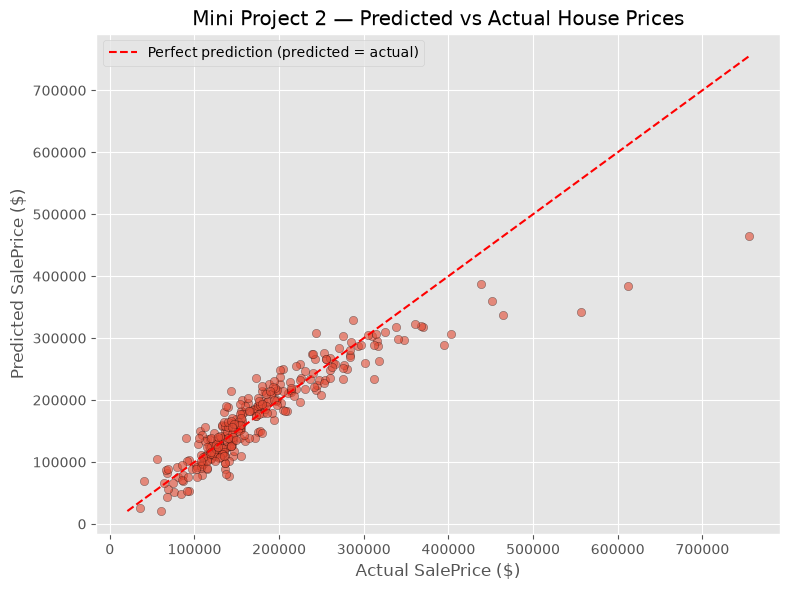

Plot saved as house_price_predicted_vs_actual.png


In [10]:
# Mini Project 2 — plot predicted vs actual values
plt.figure(figsize=(8, 6))
plt.scatter(y_test_mp, pred_mp, alpha=0.6, edgecolor="k", linewidth=0.3)
lims = [min(y_test_mp.min(), pred_mp.min()), max(y_test_mp.max(), pred_mp.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction (predicted = actual)")
plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.title("Mini Project 2 — Predicted vs Actual House Prices")
plt.legend()
plt.tight_layout()
plt.savefig("house_price_predicted_vs_actual.png", dpi=150)
plt.show()
print("Plot saved as house_price_predicted_vs_actual.png")

**Mini Project 2 result:** the full-feature Linear Regression reaches the R² printed above, clearly better than Assignment 1's six-feature model — more relevant features mean a better fit. Points cluster close to the red "perfect prediction" line; the spread grows for the most expensive houses, where prices are harder to pin down.

---
## Practice Questions — Classification Models
### Topics: Logistic Regression, Decision Tree, KNN

### Q1. Train a Logistic Regression model on the Titanic dataset
### Q2. Create the confusion matrix and accuracy score

Same cleaned Titanic data and split as Assignment 2, now with the confusion matrix shown and plotted.

In [11]:
# Practice Q1 + Q2 — Logistic Regression with confusion matrix
logreg_pq = LogisticRegression(max_iter=1000)
logreg_pq.fit(X_train_a2, y_train_a2)
pred_pq = logreg_pq.predict(X_test_a2)

acc_pq = accuracy_score(y_test_a2, pred_pq)
cm_pq = confusion_matrix(y_test_a2, pred_pq)
print("Practice Q1 + Q2 — Logistic Regression on Titanic")
print("Accuracy: %.4f (%.2f%%)" % (acc_pq, 100 * acc_pq))
print()
print("Confusion matrix  [rows = actual, columns = predicted]")
print("                  Predicted:  Did not survive | Survived")
print(cm_pq)
tn, fp, fn, tp = cm_pq.ravel()
print(f"\nTrue Negatives: {tn} | False Positives: {fp} | "
      f"False Negatives: {fn} | True Positives: {tp}")

Practice Q1 + Q2 — Logistic Regression on Titanic
Accuracy: 0.8101 (81.01%)

Confusion matrix  [rows = actual, columns = predicted]
                  Predicted:  Did not survive | Survived
[[90 15]
 [19 55]]

True Negatives: 90 | False Positives: 15 | False Negatives: 19 | True Positives: 55


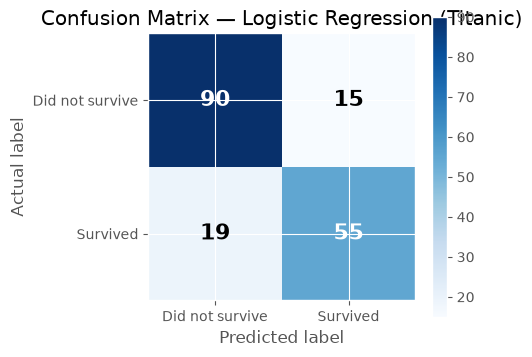

In [12]:
# Practice Q2 — plot the confusion matrix
plt.figure(figsize=(5, 4))
plt.imshow(cm_pq, cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression (Titanic)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.yticks([0, 1], ["Did not survive", "Survived"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm_pq[i, j]), ha="center", va="center",
                 fontsize=16, fontweight="bold",
                 color="white" if cm_pq[i, j] > cm_pq.max() / 2 else "black")
plt.colorbar()
plt.tight_layout()
plt.show()

### Q3. Compare DecisionTreeClassifier and KNeighborsClassifier accuracy

Both models train on the same cleaned Titanic features and the same 80/20 split, so the comparison is fair. KNN works on distances, so its features are standardised first; the Decision Tree needs no scaling.

In [13]:
# Practice Q3 — Decision Tree vs KNN on the same split
tree_pq = DecisionTreeClassifier(random_state=42)
tree_pq.fit(X_train_a2, y_train_a2)
acc_tree = accuracy_score(y_test_a2, tree_pq.predict(X_test_a2))

scaler_pq = StandardScaler()
X_train_scaled = scaler_pq.fit_transform(X_train_a2)
X_test_scaled = scaler_pq.transform(X_test_a2)
knn_pq = KNeighborsClassifier(n_neighbors=5)
knn_pq.fit(X_train_scaled, y_train_a2)
acc_knn = accuracy_score(y_test_a2, knn_pq.predict(X_test_scaled))

comparison = pd.DataFrame(
    {"Model": ["Logistic Regression", "Decision Tree", "KNN (k=5)"],
     "Accuracy": [round(acc_pq, 4),
                  round(acc_tree, 4),
                  round(acc_knn, 4)]})
print("Practice Q3 — accuracy comparison (same Titanic test set):")
print(comparison.to_string(index=False))
print()
print("Best of the three:", comparison.loc[comparison["Accuracy"].idxmax(), "Model"])

Practice Q3 — accuracy comparison (same Titanic test set):
              Model  Accuracy
Logistic Regression    0.8101
      Decision Tree    0.7877
          KNN (k=5)    0.8045

Best of the three: Logistic Regression


### Q4. Tune `max_depth` of the Decision Tree and note the difference

A Decision Tree with no depth limit keeps splitting until every training point is pure — it memorises the training data (overfitting) and usually does worse on unseen passengers. Limiting `max_depth` forces simpler, more general rules. We try depths 2, 3, 4, 5, 8, 10 and no limit, and watch train vs test accuracy.

In [14]:
# Practice Q4 — tune max_depth
depths = [2, 3, 4, 5, 8, 10, None]
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train_a2, y_train_a2)
    rows.append({
        "max_depth": "None (unlimited)" if d is None else d,
        "Train accuracy": round(accuracy_score(y_train_a2, tree.predict(X_train_a2)), 4),
        "Test accuracy": round(accuracy_score(y_test_a2, tree.predict(X_test_a2)), 4),
    })
tuning = pd.DataFrame(rows)
print("Practice Q4 — Decision Tree max_depth tuning:")
print(tuning.to_string(index=False))
best_row = tuning.loc[tuning["Test accuracy"].idxmax()]
print()
print("Best test accuracy: %.4f at max_depth = %s"
      % (best_row["Test accuracy"], best_row["max_depth"]))

Practice Q4 — Decision Tree max_depth tuning:
       max_depth  Train accuracy  Test accuracy
               2          0.8034         0.7654
               3          0.8343         0.7989
               4          0.8399         0.7989
               5          0.8497         0.7989
               8          0.8975         0.7933
              10          0.9129         0.7989
None (unlimited)          0.9789         0.7877

Best test accuracy: 0.7989 at max_depth = 3


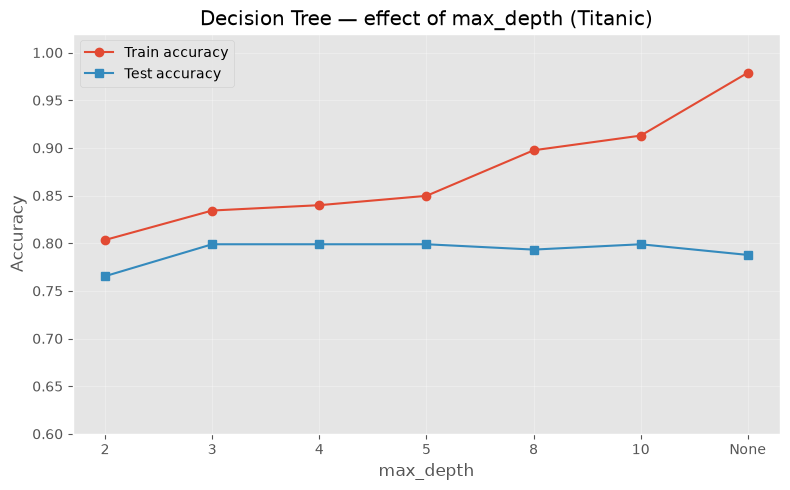

In [15]:
# Practice Q4 — plot train vs test accuracy by depth
labels = ["2", "3", "4", "5", "8", "10", "None"]
plt.figure(figsize=(8, 5))
plt.plot(labels, tuning["Train accuracy"], marker="o", label="Train accuracy")
plt.plot(labels, tuning["Test accuracy"], marker="s", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree — effect of max_depth (Titanic)")
plt.ylim(0.6, 1.02)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Practice Q4 note:** train accuracy climbs towards 1.0 as `max_depth` grows — the unlimited tree memorises the training passengers. Test accuracy peaks at a shallow depth (see the table) and then falls: that gap is overfitting. A small depth generalises better, which is why tuning matters before trusting a tree.

---
## Summary

| Item | Model / task | Key result |
|---|---|---|
| Assignment 1 | Linear Regression — housing price (6 features) | R² and RMSE printed above; living area & quality drive price |
| Assignment 2 | Logistic Regression — Titanic survival | Accuracy printed above |
| Mini Project 2 | Linear Regression — House Prices, all numeric features | R² printed above + predicted-vs-actual plot |
| Practice Q1–Q2 | Logistic Regression + confusion matrix | Accuracy printed above |
| Practice Q3 | Decision Tree vs KNN | Accuracy comparison table above |
| Practice Q4 | Decision Tree `max_depth` tuning | Best depth and test accuracy in the table above |

All models were trained and evaluated in this notebook with an 80/20 train/test split (`random_state=42`) and the metrics the Week 2 brief names: MSE, R² and the confusion matrix.